# Supplemental Figure 4, Panel C

Barcode plots showing GSEA results for inteferon response (genes ranked by IFNg vs Vehicle log2FC expression) and glucocorticoid response (genes ranked by Dex vs Vehicle log2FC expression) terms at both 1h and 6h stimulus treatment

*Output: PanelC_barcode.pdf*

In [1]:
# Setup

In [20]:
# load packages
library(tidyverse)
library(fgsea)
library(msigdbr)
library(patchwork)
library(org.Hs.eg.db)
library(AnnotationDbi)
library(pheatmap)
library(RColorBrewer)
library(here)
here::i_am("figures/SuppFig4/PanelC/PanelC.ipynb")
theme_set(theme_bw() + theme(text=element_text(size=15), panel.grid=element_blank()))

sessionInfo()

#function to deal with (rare) duplicated gene entries
collapse_deg_duplicates <- function(df,
                                    gene_col = "gene",
                                    padj_col = "padj",
                                    lfc_col  = "log2FoldChange") {
  df %>%
    filter(!is.na(.data[[gene_col]])) %>%
    group_by(.data[[gene_col]]) %>%
    arrange(.data[[padj_col]], desc(abs(.data[[lfc_col]]))) %>%
    dplyr::slice(1) %>%
    ungroup()
}

# function to run GSEA
# for IFNy and GC response terms, which can include both induced and repressed genes, use abs(logFC)
gsea_abs <- function(table, genesets){
    ranking.vals <- abs(table$log2FoldChange)
    names(ranking.vals) <- table$gene

    res <- fgsea(pathways=genesets, stats=ranking.vals,minSize=10)
    return(res)
}

#function to make GSEA barcode plot, where vertical lines represente position of GO term genes within ranked geneset
gsea_plot <- function(table, gsea_res, pathway_name, color="black"){
    ranked_genes <- table$gene[order(abs(table$log2FoldChange), decreasing=FALSE)]
    gene_set <- msigdbr_list[[pathway_name]]

    NES <- (gsea_res %>% filter(pathway==pathway_name))$NES
    p <- (gsea_res %>% filter(pathway==pathway_name))$padj
    
    df_hits <- data.frame(
        x = which(ranked_genes %in% gene_set),
        y0 = 0,
        y1 = 0.1)

    df_hits$x_scaled <- df_hits$x/length(ranked_genes)

    df_rect <- data.frame(
          xmin = 0,
          xmax = 1,
          ymin = 0,
          ymax = 0.1)
    
    plot <- ggplot() +
        geom_segment(data = df_hits, aes(x = x_scaled, xend = x_scaled, y = y0, yend = y1), linewidth=.5, color=color) +
        geom_rect(data = df_rect, aes(xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax), fill = NA, color = "black") +
        scale_x_continuous(expand=c(0,0),limits = c(0,1),breaks = c(0,1),
                           labels = c("low |l2FC|", "high |l2FC|")) +
        labs(x = pathway_name, y = NULL, 
             title=paste("NES =", format(NES, digits=3),", p =", format(p,digits=3))) +
        theme_bw(base_size = 13) +
        theme(rect=element_rect(linewidth=1),
        panel.grid = element_blank(),
        axis.ticks.y = element_blank(),
        axis.text.y = element_blank()
        ) + 
        coord_fixed()
    
   return(plot) 
}


here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] here_1.0.2           RColorBrewer_1.1-3   pheatmap_1.0.12     
 [4] org.Hs.eg.db_3.16.0  AnnotationDbi_1.60.2 IRanges_2.32.0      
 [7] S4Vectors_0.36.2     Biobase_2.58.0       BiocGenerics_0.44.0 
[10] patchwork_1.3.0      msigdbr_7.5.1        fgsea_1.24.0        
[13] lub

# Load data

In [2]:
#read in DEGs
ifn_1h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep", "IFN_1h_DEGs.tsv"),
  sep = "\t"
)

ifn_6h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep", "IFN_6h_DEGs.tsv"),
  sep = "\t"
)

dex_1h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep", "Dex_1h_DEGs.tsv"),
  sep = "\t"
)

dex_6h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep", "Dex_6h_DEGs.tsv"),
  sep = "\t"
)


# load msigdbr GO:BP terms and filter for IFNg and GC response terms

In [3]:
#get gene sets from msigdb (GO:BP terms)
all_gene_sets = msigdbr(species = "Homo sapiens")
keeper.cats <- c("GO:BP")
all_gene_sets <- all_gene_sets[which(all_gene_sets$gs_subcat %in% keeper.cats),]


#convert terms to fgsea_compatible format
msigdbr_list = split(x = all_gene_sets$gene_symbol, f = all_gene_sets$gs_name)

#add glucocorticoid response GO term 
# 1) map GO -> Entrez IDs
entrez_ids <- as.list(org.Hs.egGO2ALLEGS)[["GO:0071385"]]

# 2) map Entrez -> gene symbols
genes_df <- AnnotationDbi::select(org.Hs.eg.db,
                                  keys = entrez_ids,
                                  keytype = "ENTREZID",
                                  columns = c("SYMBOL"))
genes <- unique(genes_df$SYMBOL)
genes <- genes[!is.na(genes) & genes != ""]
length(genes); head(genes)
msigdbr_list[["GOBP_CELLULAR_RESPONSE_TO_GLUCOCORTICOID_STIMULUS"]] <- genes

msigdbr_list_stim <- msigdbr_list[which(grepl("GOBP_CELLULAR_RESPONSE_TO_GLUCOCORTICOID_STIMULUS|GOBP_RESPONSE_TO_INTERFERON_GAMMA", names(msigdbr_list)))]

'select()' returned many:1 mapping between keys and columns



[1] 55

[1] "ACVR1"  "ANXA1"  "AQP1"   "ARG1"   "ASS1"   "ATP2B1"

# run GSEA

In [21]:
#run GSEA on IFNy and Dex-treatment differential gene expression results
set.seed(123)
ifn_1h_gsea <- gsea_abs(ifn_1h, msigdbr_list_stim)
ifn_6h_gsea <- gsea_abs(ifn_6h, msigdbr_list_stim)

dex_1h_gsea <- gsea_abs(dex_1h, msigdbr_list_stim)
dex_6h_gsea <- gsea_abs(dex_6h, msigdbr_list_stim)


Warning message in preparePathwaysAndStats(pathways, stats, minSize, maxSize, gseaParam, :
“There are duplicate gene names, fgsea may produce unexpected results.”
Warning message in preparePathwaysAndStats(pathways, stats, minSize, maxSize, gseaParam, :
“There are duplicate gene names, fgsea may produce unexpected results.”
Warning message in preparePathwaysAndStats(pathways, stats, minSize, maxSize, gseaParam, :
“There are duplicate gene names, fgsea may produce unexpected results.”
Warning message in preparePathwaysAndStats(pathways, stats, minSize, maxSize, gseaParam, :
“There are duplicate gene names, fgsea may produce unexpected results.”


# Generate plots

In [22]:
#plot results
p1 <- gsea_plot(ifn_1h, ifn_1h_gsea, "GOBP_RESPONSE_TO_INTERFERON_GAMMA", color="#1c9e77")
p2 <- gsea_plot(ifn_6h, ifn_6h_gsea, "GOBP_RESPONSE_TO_INTERFERON_GAMMA", color="#127555")

p3 <- gsea_plot(dex_1h, dex_1h_gsea, "GOBP_CELLULAR_RESPONSE_TO_GLUCOCORTICOID_STIMULUS", color="#5791c9")
p4 <- gsea_plot(dex_6h, dex_6h_gsea, "GOBP_CELLULAR_RESPONSE_TO_GLUCOCORTICOID_STIMULUS", color="#4878a6")


# Assemble figure panel

Saving 4 x 7 in image


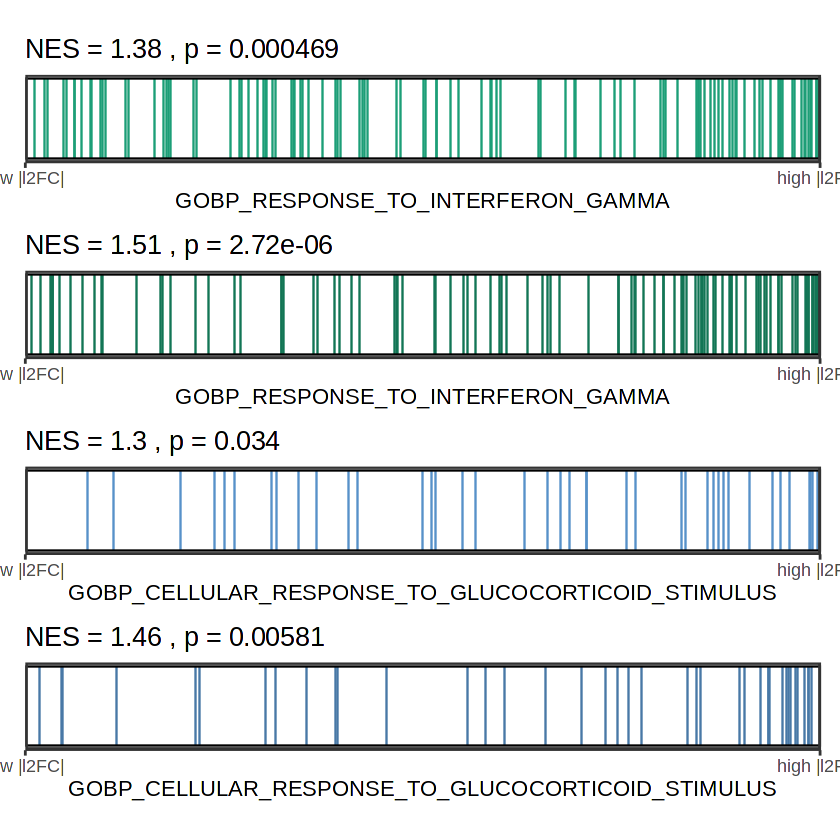

In [24]:
p1 / p2 / p3/ p4
ggsave("PanelC_GSEA_barcode.pdf", width=4)